# Animal Detection Model Training with EfficientNetB0

## 1. Import Required Libraries

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image_dataset_from_directory
import matplotlib.pyplot as plt
import os

## 2. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Set Data Path

In [ ]:
DATA_DIR = "/content/drive/MyDrive/Animal Detection/animal_dataset"

## 4. Load and Prepare Datasets

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)
val_ds = image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)

## 5. Optimize Dataset Performance

Cache data and apply prefetching to improve training speed. Shuffle training data for better model generalization.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

## 6. Data Augmentation

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

## 7. Build Transfer Learning Model

In [ ]:
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,)
)
base_model.trainable = False

inputs = layers.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## 8. Compile Model

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 28)             │        35,868 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,085,439 (15.58 MB)

 Trainable params: 35,868 (140.11 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 9. Initial Training

In [ ]:
EPOCHS = 25

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 513s 4s/step - accuracy: 0.2184 - loss: 3.0014 - val_accuracy: 0.7560 - val_loss: 1.5177
Epoch 2/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 121s 3s/step - accuracy: 0.7600 - loss: 1.3649 - val_accuracy: 0.8333 - val_loss: 0.8384
Epoch 3/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 141s 3s/step - accuracy: 0.8389 - loss: 0.8509 - val_accuracy: 0.8720 - val_loss: 0.6120
Epoch 4/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 145s 3s/step - accuracy: 0.8660 - loss: 0.6556 - val_accuracy: 0.8958 - val_loss: 0.5081
Epoch 5/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 120s 3s/step - accuracy: 0.9078 - loss: 0.4765 - val_accuracy: 0.8958 - val_loss: 0.4397
Epoch 6/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 128s 3s/step - accuracy: 0.9109 - loss: 0.4186 - val_accuracy: 0.8988 - val_loss: 0.3948
Epoch 7/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 135s 3s/step - accuracy: 0.9345 - loss: 0.3380 - val_accuracy: 0.9167 - val_loss: 0.3612
Epoch 8/25
42/42 ━━━━━━━━━━━━━━━━━━━━ 121s 3s/step - accuracy: 0.9380 - loss: 0.3197 - val_accuracy: 0.9107 - v

In [ ]:
base_model.trainable = True

## 10. Prepare Fine-tuning

In [ ]:
fine_tune_at = int(len(base_model.layers) * 0.8)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 11. Fine-tuning Training

In [ ]:
fine_tune_epochs = 10
total_epochs = EPOCHS + fine_tune_epochs

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=history.epoch[-1]
)

Epoch 25/35
42/42 ━━━━━━━━━━━━━━━━━━━━ 24s 169ms/step - accuracy: 0.8914 - loss: 0.5016 - val_accuracy: 0.9077 - val_loss: 0.2682
Epoch 26/35
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - accuracy: 0.8946 - loss: 0.4850 - val_accuracy: 0.9077 - val_loss: 0.2901
Epoch 27/35
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - accuracy: 0.8960 - loss: 0.4226 - val_accuracy: 0.9018 - val_loss: 0.3094
Epoch 28/35
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step - accuracy: 0.9084 - loss: 0.4241 - val_accuracy: 0.8988 - val_loss: 0.3234
Epoch 29/35
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - accuracy: 0.9237 - loss: 0.3687 - val_accuracy: 0.8988 - val_loss: 0.3332
Epoch 30/35
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - accuracy: 0.9239 - loss: 0.3751 - val_accuracy: 0.8929 - val_loss: 0.3376
Epoch 31/35
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step - accuracy: 0.9242 - loss: 0.3422 - val_accuracy: 0.8899 - val_loss: 0.3398
Epoch 32/35
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - accuracy: 0.9366 - loss: 0.3247 - val_acc

## 12. Visualize Training History

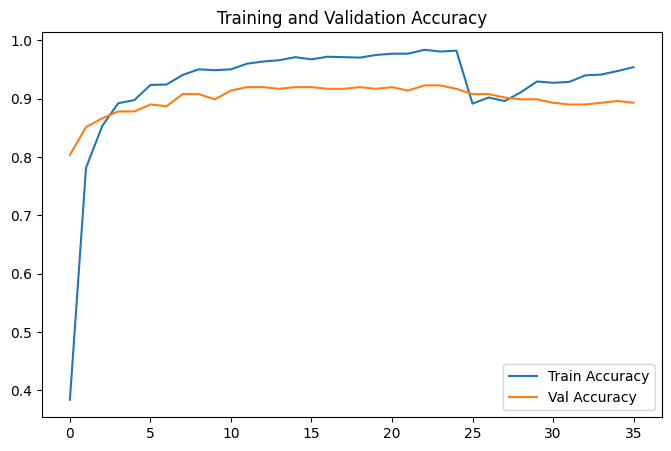

In [ ]:
acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']

plt.figure(figsize=(8, 5))
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Val Accuracy')
plt.legend()
plt.title("Training and Validation Accuracy")
plt.show()

## 13. Save Trained Model

In [ ]:
model.save("/content/animal_classifier_efficientnet.h5")

## 14. Test Model Predictions

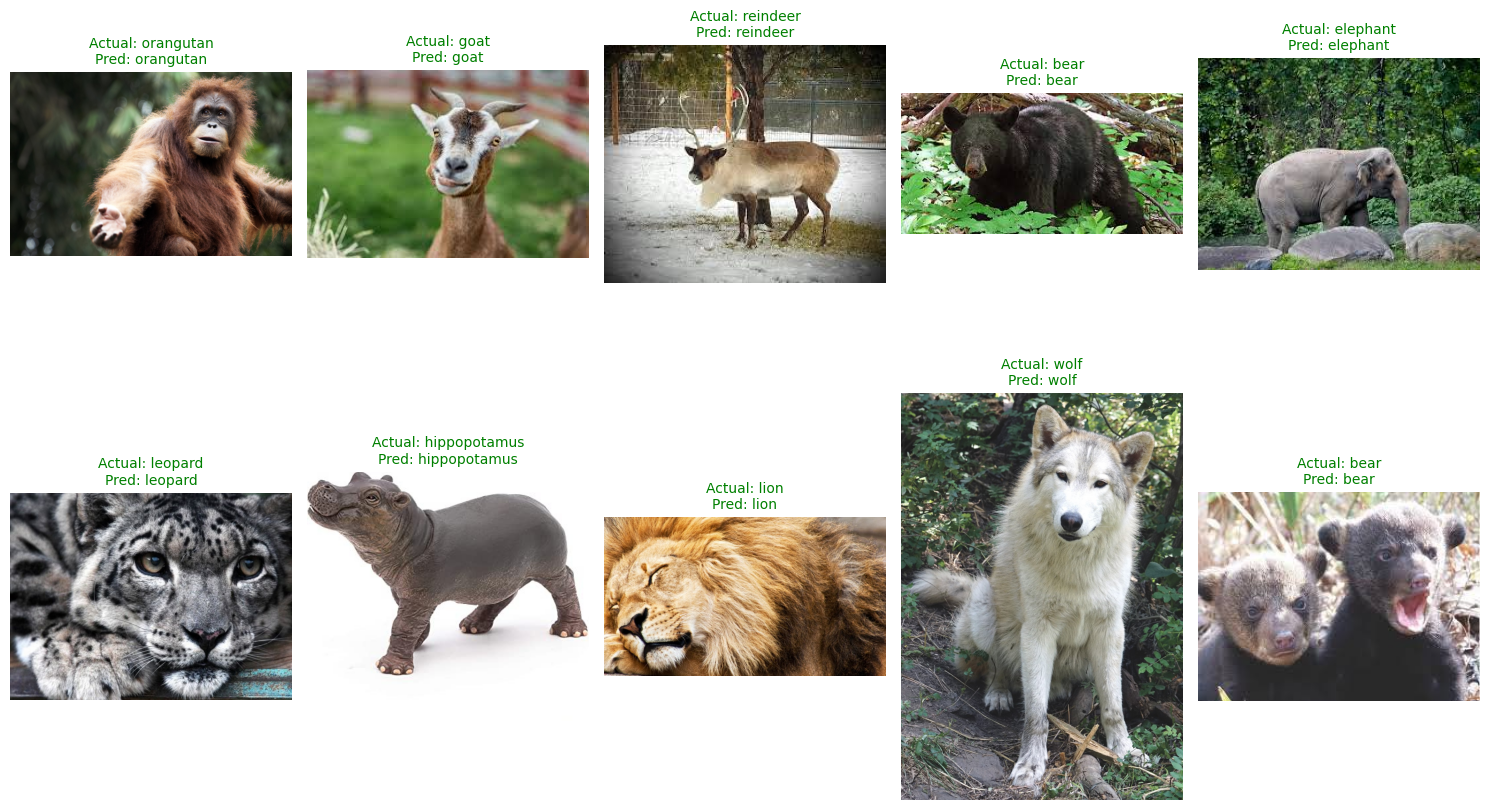

In [ ]:
import random
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt


from tensorflow.keras.models import load_model
model = load_model("/content/animal_classifier_efficientnet.h5")

val_dir = os.path.join(DATA_DIR)
all_images = []
for label in class_names:
    folder = os.path.join(val_dir, label)
    imgs = [os.path.join(folder, f) for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
    all_images.extend(imgs)

sample_images = random.sample(all_images, 10)


plt.figure(figsize=(15, 10))

for i, img_path in enumerate(sample_images):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = tf.keras.applications.efficientnet.preprocess_input(img_array)

    preds = model.predict(img_array, verbose=0)
    pred_class = class_names[np.argmax(preds)]

    actual_class = os.path.basename(os.path.dirname(img_path))

    plt.subplot(2, 5, i + 1)
    plt.imshow(image.load_img(img_path))
    plt.axis("off")
    color = "green" if pred_class == actual_class else "red"
    plt.title(f"Actual: {actual_class}\nPred: {pred_class}", color=color, fontsize=10)

plt.tight_layout()
plt.show()
